# Arbitrary Compartment Simulation with an Acquisition Preset

This notebook builds a custom multi-compartment model and simulates its signal using an HCP-style acqusition.
We then fit the data using the NODDI model (without dispersion).
Note this notebook does not include FOD simulation and assumes there is a single stick.
FOD simulation has since been included. See notebook 02 for full NODDI fitting.

In [2]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt

from dmri_models import Ball, Component, Model, Sphere, Stick, Tensor, Zeppelin
from dmri_models.acquisitions import bigmac_highres, hcp

rng = np.random.default_rng(42)
print(f"Repository root: {repo_root}")

Repository root: /Users/Ronan/Documents/PhD/Tools/microstructure-mri-main


----------------------------------------------------------------
Acquisition summary
- measurements: 288
- b-value shells (ms/um^2): 4 (tolerance: 0.100)
  - b=0.000: 18 measurements, 18 non-zero directions
  - b=0.998: 90 measurements, 90 non-zero directions
  - b=1.998: 90 measurements, 90 non-zero directions
  - b=2.996: 90 measurements, 90 non-zero directions
- gradient directions: 288 unique non-zero across 288 diffusion-weighted measurements
- b-tensor shape: 1.000
- pulse duration (ms): 10.600
- diffusion time (ms): 43.100
- gradient strength (T/m): 0.000 to 0.097
- echo time (ms): 89.500
- inversion time: n/a
- repetition time (ms): 5520.000
----------------------------------------------------------------
Number of measurements: 288
Signal range: [0.001, 1.000]


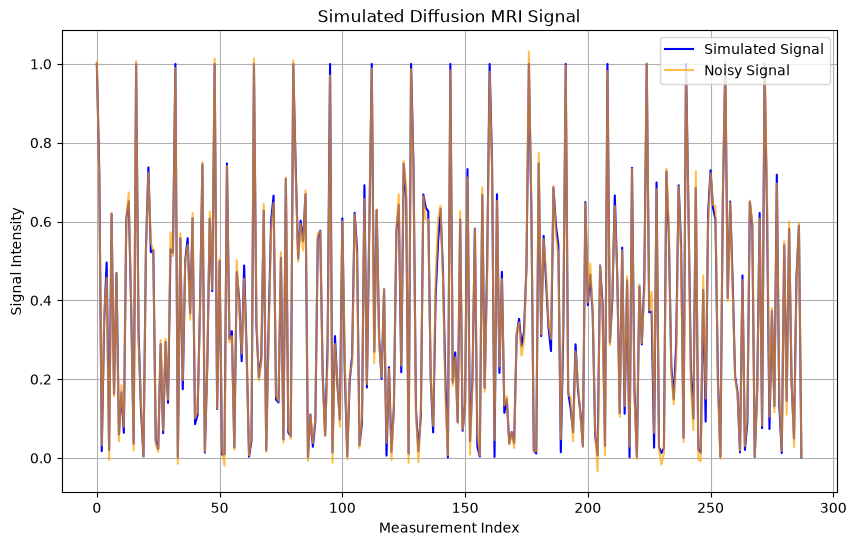

In [4]:
# Define the acquisition scheme - here use HCP acquisition scheme as an example
acquisition = hcp()

# Output summary of the acquisition
acquisition.print_summary()

# Define the model with three compartments: extra-cellular space (Ball), neurites (Stick), and soma (Sphere)
# First, we create the compartments
model = Model(
    [
        Component("extra", Zeppelin(parallel_diffusivity="d_par", perpendicular_diffusivity="d_perp", orientation="axis")),
        Component("neurite", Stick(diffusivity="d_in", orientation="axis")),
        Component("csf", Ball(diffusivity="d_csf")),
        #Component("extra", Tensor()),
        #Component("soma", Sphere(radius="r_soma",diffusivity="d_sphere")),
        
    ]
)
# Then define the parameters for the model
parameters = {
    "S0": 1.0,
    "extra_fraction": 0.30,
    "neurite_fraction": 0.60,
    "csf_fraction": 0.10,
    "d_par": 2.2,   
    "d_in": 2.2,
    "d_perp": 0.6,
    "d_csf": 3.0,
    "axis": np.array([0.2, 0.7, 0.6]),
}

# Make d_perp the simulation consistent with the NODDI tortuosity model used in fitting:
# v_ic = f_neurite / (1 - f_csf), d_perp = (1 - v_ic) * d_par
v_ic_truth = parameters["neurite_fraction"] / (1.0 - parameters["csf_fraction"])
parameters["d_perp"] = (1.0 - v_ic_truth) * parameters["d_par"]

# Simulate the signal
signal = model.signal(acquisition, parameters)
# Add Gaussian noise 
SNR = 50  # Signal-to-noise ratio
noisy_signal = signal + rng.normal(0.0, parameters["S0"]/SNR, size=signal.shape)

print(f"Number of measurements: {acquisition.n_measurements}")
print(f"Signal range: [{signal.min():.3f}, {signal.max():.3f}]")


# Plot the simulated signal
plt.figure(figsize=(10, 6))
plt.plot(signal, label="Simulated Signal", color='blue')
plt.plot(noisy_signal, label="Noisy Signal", color='orange', alpha=0.7)
plt.title("Simulated Diffusion MRI Signal")
plt.xlabel("Measurement Index")
plt.ylabel("Signal Intensity")
plt.legend()
plt.grid()

## Non-linear parameter estimation (NODDI-style constraints)

Estimate parameters from the simulated noisy signal using non-linear least squares.

Assumptions used in the fit:
- `d_csf` is known and fixed.
- `d_in` is fixed to `2.2` (NODDI-style).
- `d_par = d_in`.
- `d_perp = (1 - v_ic) * d_par` (NODDI tortuosity, no dispersion).
- Fractions are parameterised as `v_iso` and `v_ic`, then mapped to:
  `f_csf = v_iso`, `f_neurite = (1 - v_iso) * v_ic`, `f_extra = (1 - v_iso) * (1 - v_ic)`.
- Orientation is parameterised by spherical angles `theta` and `phi`.
- Initialisation is chosen close to the ground truth.

Fit status: `ftol` termination condition is satisfied.
Cost (sum of squares / 2): 4.920302e-02
Estimated NODDI coordinates:
  v_iso = 0.1014 (true 0.1000)
  v_ic  = 0.6695 (true 0.6667)
Estimated fractions:
  extra   = 0.2970 (true 0.3000)
  neurite = 0.6016 (true 0.6000)
  csf     = 0.1014 (true 0.1000)
Estimated S0: 0.9973 (true 1.0000)
Estimated d_perp: 0.7271 (true 0.7333)
Estimated theta, phi: (0.8822, 1.2943)


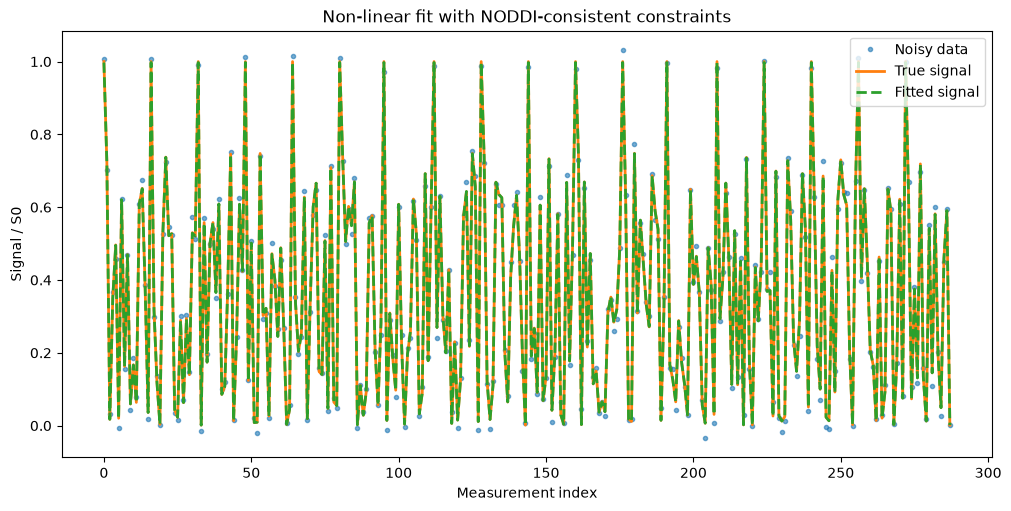

In [5]:
from scipy.optimize import least_squares

def unit_vector_from_angles(theta: float, phi: float) -> np.ndarray:
    return np.array([
        np.sin(theta) * np.cos(phi),
        np.sin(theta) * np.sin(phi),
        np.cos(theta),
    ])

def sigmoid(x: float | np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-x))

def noddi_fraction_map(z_iso: float, z_ic: float) -> tuple[float, float, float, float, float]:
    v_iso = float(sigmoid(z_iso))
    v_ic = float(sigmoid(z_ic))
    f_csf = v_iso
    f_neurite = (1.0 - v_iso) * v_ic
    f_extra = (1.0 - v_iso) * (1.0 - v_ic)
    return v_iso, v_ic, f_extra, f_neurite, f_csf

# Fixed diffusivities (NODDI-style assumptions)
d_in_fixed = 2.2
d_csf_fixed = 3.0
d_par_fixed = d_in_fixed

axis_true = np.asarray(parameters["axis"], dtype=float)
axis_true = axis_true / np.linalg.norm(axis_true)
theta_true = float(np.arccos(np.clip(axis_true[2], -1.0, 1.0)))
phi_true = float(np.arctan2(axis_true[1], axis_true[0]))

# Convert truth fractions to NODDI-like coordinates
f_extra_true = float(parameters["extra_fraction"])
f_neurite_true = float(parameters["neurite_fraction"])
f_csf_true = float(parameters["csf_fraction"])
v_iso_true = f_csf_true
v_ic_true = f_neurite_true / max(1e-8, 1.0 - f_csf_true)

eps = 1e-8
x0 = np.array([
    float(parameters["S0"]) * 1.02,
    np.log((v_iso_true + eps) / (1.0 - v_iso_true + eps)) + 0.05,
    np.log((v_ic_true + eps) / (1.0 - v_ic_true + eps)) - 0.05,
    theta_true + 0.03,
    phi_true - 0.03,
])

def residuals(x: np.ndarray) -> np.ndarray:
    S0_fit, z_iso, z_ic, theta, phi = x
    v_iso, v_ic, f_extra, f_neurite, f_csf = noddi_fraction_map(z_iso, z_ic)
    d_perp = (1.0 - v_ic) * d_par_fixed
    axis = unit_vector_from_angles(theta, phi)

    fit_params = {
        "S0": S0_fit,
        "extra_fraction": f_extra,
        "neurite_fraction": f_neurite,
        "csf_fraction": f_csf,
        "d_par": d_par_fixed,
        "d_perp": d_perp,
        "d_in": d_in_fixed,
        "d_csf": d_csf_fixed,
        "axis": axis,
    }
    return model.signal(acquisition, fit_params) - noisy_signal

result = least_squares(
    residuals,
    x0,
    bounds=([0.1, -8.0, -8.0, 0.0, -np.pi], [2.0, 8.0, 8.0, np.pi, np.pi]),
    method="trf",
)

S0_hat, z_iso_hat, z_ic_hat, theta_hat, phi_hat = result.x
v_iso_hat, v_ic_hat, f_extra_hat, f_neurite_hat, f_csf_hat = noddi_fraction_map(
    z_iso_hat, z_ic_hat
)
axis_hat = unit_vector_from_angles(theta_hat, phi_hat)
d_perp_hat = (1.0 - v_ic_hat) * d_par_fixed

fitted_params = {
    "S0": S0_hat,
    "extra_fraction": f_extra_hat,
    "neurite_fraction": f_neurite_hat,
    "csf_fraction": f_csf_hat,
    "d_par": d_par_fixed,
    "d_perp": d_perp_hat,
    "d_in": d_in_fixed,
    "d_csf": d_csf_fixed,
    "axis": axis_hat,
}
fitted_signal = model.signal(acquisition, fitted_params)

print("Fit status:", result.message)
print(f"Cost (sum of squares / 2): {result.cost:.6e}")
print("Estimated NODDI coordinates:")
print(f"  v_iso = {v_iso_hat:.4f} (true {v_iso_true:.4f})")
print(f"  v_ic  = {v_ic_hat:.4f} (true {v_ic_true:.4f})")
print("Estimated fractions:")
print(f"  extra   = {f_extra_hat:.4f} (true {parameters['extra_fraction']:.4f})")
print(f"  neurite = {f_neurite_hat:.4f} (true {parameters['neurite_fraction']:.4f})")
print(f"  csf     = {f_csf_hat:.4f} (true {parameters['csf_fraction']:.4f})")
print(f"Estimated S0: {S0_hat:.4f} (true {parameters['S0']:.4f})")
print(f"Estimated d_perp: {d_perp_hat:.4f} (true {parameters['d_perp']:.4f})")
print(f"Estimated theta, phi: ({theta_hat:.4f}, {phi_hat:.4f})")

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.plot(noisy_signal, '.', alpha=0.6, label='Noisy data')
ax.plot(signal, '-', linewidth=2, label='True signal')
ax.plot(fitted_signal, '--', linewidth=2, label='Fitted signal')
ax.set_title('Non-linear fit with NODDI-consistent constraints')
ax.set_xlabel('Measurement index')
ax.set_ylabel('Signal / S0')
ax.legend()
plt.show()

## Monte Carlo identifiability check

Repeat the constrained non-linear fit across many independent noise realisations to estimate parameter bias and variability at the chosen SNR.

Monte Carlo repeats: 100
Optimiser success rate: 100.0%

Parameter recovery summary (mean ± sd, bias):
         S0:  1.0001 ± 0.0040  | bias +0.0001  (true 1.0000)
      v_iso:  0.1000 ± 0.0140  | bias +0.0000  (true 0.1000)
       v_ic:  0.6669 ± 0.0111  | bias +0.0002  (true 0.6667)
    f_extra:  0.2999 ± 0.0145  | bias -0.0001  (true 0.3000)
  f_neurite:  0.6000 ± 0.0032  | bias +0.0000  (true 0.6000)
      f_csf:  0.1000 ± 0.0140  | bias +0.0000  (true 0.1000)
     d_perp:  0.7328 ± 0.0245  | bias -0.0005  (true 0.7333)
      theta:  0.8815 ± 0.0024  | bias +0.0001  (true 0.8815)
        phi:  1.2922 ± 0.0034  | bias -0.0002  (true 1.2925)


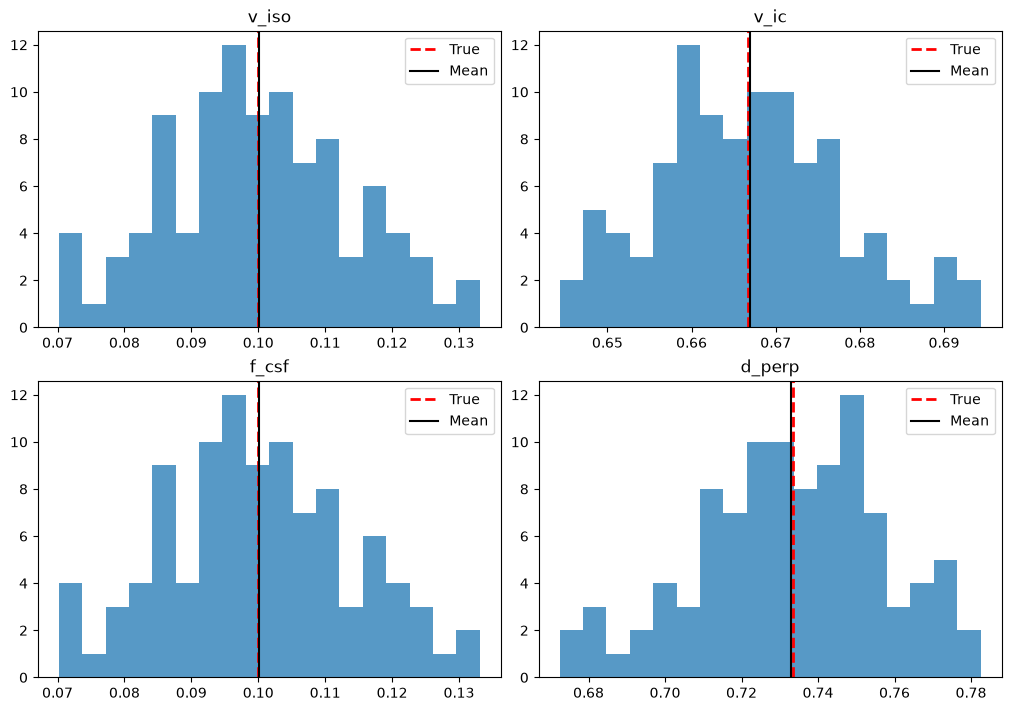

In [4]:
n_repeats = 100
mc_rng = np.random.default_rng(123)

def fit_single_realisation(data: np.ndarray, x_start: np.ndarray) -> tuple[np.ndarray, bool]:
    def residuals_local(x: np.ndarray) -> np.ndarray:
        S0_fit, z_iso, z_ic, theta, phi = x
        _, v_ic, f_extra, f_neurite, f_csf = noddi_fraction_map(z_iso, z_ic)
        d_perp = (1.0 - v_ic) * d_par_fixed
        axis = unit_vector_from_angles(theta, phi)
        fit_params = {
            "S0": S0_fit,
            "extra_fraction": f_extra,
            "neurite_fraction": f_neurite,
            "csf_fraction": f_csf,
            "d_par": d_par_fixed,
            "d_perp": d_perp,
            "d_in": d_in_fixed,
            "d_csf": d_csf_fixed,
            "axis": axis,
        }
        return model.signal(acquisition, fit_params) - data

    out = least_squares(
        residuals_local,
        x_start,
        bounds=([0.1, -8.0, -8.0, 0.0, -np.pi], [2.0, 8.0, 8.0, np.pi, np.pi]),
        method="trf",
    )
    return out.x, bool(out.success)

estimates = []
success_flags = []

for _ in range(n_repeats):
    y = signal + mc_rng.normal(0.0, parameters["S0"] / SNR, size=signal.shape)
    x_hat, ok = fit_single_realisation(y, x0)
    success_flags.append(ok)

    S0_i, z_iso_i, z_ic_i, theta_i, phi_i = x_hat
    v_iso_i, v_ic_i, f_extra_i, f_neurite_i, f_csf_i = noddi_fraction_map(z_iso_i, z_ic_i)
    d_perp_i = (1.0 - v_ic_i) * d_par_fixed
    estimates.append(
        [
            S0_i,
            v_iso_i,
            v_ic_i,
            f_extra_i,
            f_neurite_i,
            f_csf_i,
            d_perp_i,
            theta_i,
            phi_i,
        ]
    )

estimates = np.asarray(estimates, dtype=float)
success_rate = np.mean(success_flags)

param_names = [
    "S0",
    "v_iso",
    "v_ic",
    "f_extra",
    "f_neurite",
    "f_csf",
    "d_perp",
    "theta",
    "phi",
]
true_values = np.array([
    parameters["S0"],
    v_iso_true,
    v_ic_true,
    parameters["extra_fraction"],
    parameters["neurite_fraction"],
    parameters["csf_fraction"],
    parameters["d_perp"],
    theta_true,
    phi_true,
])

means = estimates.mean(axis=0)
stds = estimates.std(axis=0, ddof=1)
bias = means - true_values

print(f"Monte Carlo repeats: {n_repeats}")
print(f"Optimiser success rate: {100 * success_rate:.1f}%")
print("\nParameter recovery summary (mean ± sd, bias):")
for name, mu, sd, b, truth in zip(param_names, means, stds, bias, true_values, strict=True):
    print(f"  {name:>9s}: {mu: .4f} ± {sd:.4f}  | bias {b:+.4f}  (true {truth:.4f})")

fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
plot_items = [
    (1, "v_iso"),
    (2, "v_ic"),
    (5, "f_csf"),
    (6, "d_perp"),
]

for ax, (idx, label) in zip(axes.ravel(), plot_items, strict=True):
    ax.hist(estimates[:, idx], bins=18, alpha=0.75)
    ax.axvline(true_values[idx], color="red", linestyle="--", linewidth=2, label="True")
    ax.axvline(means[idx], color="black", linestyle="-", linewidth=1.5, label="Mean")
    ax.set_title(label)
    ax.legend()

plt.show()

## Add 10 extra b=500 directions: impact on CSF robustness

This section augments the acquisition with 10 additional diffusion directions at `b=500 s/mm^2` (i.e. `0.5 ms/um^2`), then repeats the Monte Carlo analysis to compare CSF estimation stability and bias.

CSF fraction recovery comparison (100 Monte Carlo repeats)
  True f_csf: 0.1000
  Base acquisition: mean=0.1029, sd=0.0153, bias=+0.0029
  +10 dirs at b=500: mean=0.1001, sd=0.0140, bias=+0.0001


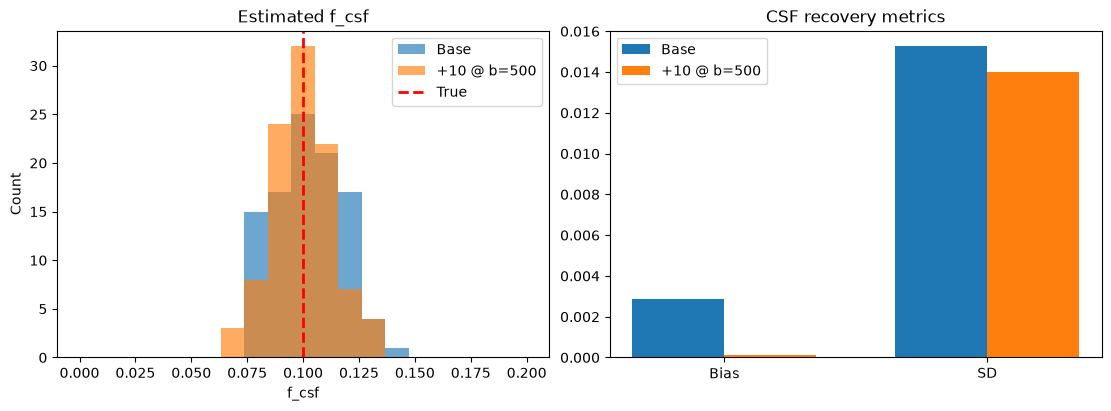

In [5]:
from dmri_models import Acquisition

def fibonacci_directions(n: int) -> np.ndarray:
    idx = np.arange(n, dtype=float)
    z = 1.0 - 2.0 * (idx + 0.5) / n
    theta = np.pi * (1.0 + np.sqrt(5.0)) * idx
    r = np.sqrt(np.maximum(0.0, 1.0 - z**2))
    x = r * np.cos(theta)
    y = r * np.sin(theta)
    return np.column_stack((x, y, z))

def augment_with_low_b_directions(acq: Acquisition, n_new: int = 10, b_s_mm2: float = 500.0) -> Acquisition:
    new_dirs = fibonacci_directions(n_new)
    new_b = np.full(n_new, b_s_mm2 * 1e-3, dtype=float)  # convert s/mm^2 -> ms/um^2

    # Use existing timing metadata for the added measurements
    delta = float(acq.pulse_duration[0])
    big_delta = float(acq.diffusion_time[0])
    te = None if acq.echo_time is None else np.concatenate([acq.echo_time, np.full(n_new, acq.echo_time[0])])
    tr = None if acq.repetition_time is None else np.concatenate([acq.repetition_time, np.full(n_new, acq.repetition_time[0])])

    b_aug = np.concatenate([acq.b_values, new_b])
    g_aug = np.vstack([acq.gradients, new_dirs])
    beta_aug = None if acq.b_tensor_shape is None else np.concatenate([acq.b_tensor_shape, np.full(n_new, acq.b_tensor_shape[0])])

    return Acquisition.from_pgse(
        b_aug,
        b_unit="ms/um^2",
        pulse_duration=delta,
        diffusion_time=big_delta,
        gradients=g_aug,
        normalize_gradients=False,
        b_tensor_shape=beta_aug,
        echo_time=te,
        repetition_time=tr,
    )

def fit_single_realisation_for_acq(acq: Acquisition, data: np.ndarray, x_start: np.ndarray) -> tuple[np.ndarray, bool]:
    def residuals_local(x: np.ndarray) -> np.ndarray:
        S0_fit, z_iso, z_ic, theta, phi = x
        _, v_ic, f_extra, f_neurite, f_csf = noddi_fraction_map(z_iso, z_ic)
        d_perp = (1.0 - v_ic) * d_par_fixed
        axis = unit_vector_from_angles(theta, phi)
        fit_params = {
            "S0": S0_fit,
            "extra_fraction": f_extra,
            "neurite_fraction": f_neurite,
            "csf_fraction": f_csf,
            "d_par": d_par_fixed,
            "d_perp": d_perp,
            "d_in": d_in_fixed,
            "d_csf": d_csf_fixed,
            "axis": axis,
        }
        return model.signal(acq, fit_params) - data

    out = least_squares(
        residuals_local,
        x_start,
        bounds=([0.1, -8.0, -8.0, 0.0, -np.pi], [2.0, 8.0, 8.0, np.pi, np.pi]),
        method="trf",
    )
    return out.x, bool(out.success)

def monte_carlo_csf_stats(acq: Acquisition, n_samples: int = 100, seed: int = 0) -> tuple[np.ndarray, np.ndarray]:
    local_rng = np.random.default_rng(seed)
    clean = model.signal(acq, parameters)
    f_csf_vals = []
    v_iso_vals = []
    for _ in range(n_samples):
        y = clean + local_rng.normal(0.0, parameters["S0"] / SNR, size=clean.shape)
        x_hat, _ = fit_single_realisation_for_acq(acq, y, x0)
        _, _, _, _, f_csf = noddi_fraction_map(x_hat[1], x_hat[2])
        v_iso = float(sigmoid(x_hat[1]))
        f_csf_vals.append(f_csf)
        v_iso_vals.append(v_iso)
    return np.asarray(f_csf_vals), np.asarray(v_iso_vals)

acquisition_aug = augment_with_low_b_directions(acquisition, n_new=10, b_s_mm2=500.0)

f_csf_base, v_iso_base = monte_carlo_csf_stats(acquisition, n_samples=100, seed=7)
f_csf_aug, v_iso_aug = monte_carlo_csf_stats(acquisition_aug, n_samples=100, seed=7)

print("CSF fraction recovery comparison (100 Monte Carlo repeats)")
print(f"  True f_csf: {parameters['csf_fraction']:.4f}")
print(f"  Base acquisition: mean={f_csf_base.mean():.4f}, sd={f_csf_base.std(ddof=1):.4f}, bias={f_csf_base.mean()-parameters['csf_fraction']:+.4f}")
print(f"  +10 dirs at b=500: mean={f_csf_aug.mean():.4f}, sd={f_csf_aug.std(ddof=1):.4f}, bias={f_csf_aug.mean()-parameters['csf_fraction']:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
bins = np.linspace(0.0, max(0.2, f_csf_base.max(), f_csf_aug.max()), 20)

axes[0].hist(f_csf_base, bins=bins, alpha=0.65, label="Base")
axes[0].hist(f_csf_aug, bins=bins, alpha=0.65, label="+10 @ b=500")
axes[0].axvline(parameters["csf_fraction"], color="red", linestyle="--", linewidth=2, label="True")
axes[0].set_title("Estimated f_csf")
axes[0].set_xlabel("f_csf")
axes[0].set_ylabel("Count")
axes[0].legend()

summary_labels = ["Bias", "SD"]
base_vals = [f_csf_base.mean() - parameters["csf_fraction"], f_csf_base.std(ddof=1)]
aug_vals = [f_csf_aug.mean() - parameters["csf_fraction"], f_csf_aug.std(ddof=1)]
x = np.arange(len(summary_labels))
w = 0.35
axes[1].bar(x - w / 2, base_vals, width=w, label="Base")
axes[1].bar(x + w / 2, aug_vals, width=w, label="+10 @ b=500")
axes[1].set_xticks(x, summary_labels)
axes[1].set_title("CSF recovery metrics")
axes[1].legend()

plt.show()